# Lab 06 — Robustness to Real Sample Definition

### Graded Lab 3 · Student edition

**Course:** MSc Astrostatistics for Observational Cosmology **Format:** 4-hour in-class practical + extended graded analysis **Data:** published Pantheon+ / SH0ES standardized magnitudes and STAT+SYS covariance **Submission:** one executed notebook plus the required HTML/PDF export **Assessment:** graded extension contributes **5% of the course grade**

> ## Scientific question
> **How stable is the inferred cosmology under defensible changes to the
> observed sample definition?**

This lab deliberately keeps the statistical model fixed and changes the **observed sample definition**. The purpose is to diagnose robustness, not to search for a subset that gives a preferred cosmological result.

## Scope and non-negotiable distinction

This is a **real-data sensitivity analysis**.

It is **not** a formal reconstruction of the Pantheon+ survey selection function.

The Week 6 lecture derived

$$
p(D\mid\theta,S=1)
=
\frac{
p(S=1\mid D,\theta)\,p(D\mid\theta)
}{
P(S=1\mid\theta)
}.
$$

Lab 06 does not estimate either selection term in this expression. Therefore:

$$
\boxed{
\text{sample-cut sensitivity}
\neq
\text{selection-function correction}.
}
$$

Do not claim that a cut removes Malmquist bias or makes the sample unbiased.

## What remains fixed and what changes

Across every compulsory variant, keep fixed:

- the flat matter–$\Lambda$ cosmological model;
- $H_0=70\ {\rm km\,s^{-1}\,Mpc^{-1}}$ as a magnitude zero-point convention;
- uniform priors
$0.10<\Omega_m<0.60$ and $-20.2<M_B<-18.2$ mag;
- the Pantheon+ **STAT+SYS covariance**;
- the same grid resolution;
- the same posterior-summary convention.

Only the sample mask changes.

This design is essential. If the covariance model, priors and sample definition all change together, the source of a posterior shift becomes ambiguous.

## Intended learning outcomes and practical timeline

After this exercise you should be able to:

1. define a reproducible baseline Pantheon+ teaching sample;
2. subset a covariance matrix without breaking row alignment;
3. repeat the same posterior calculation under fixed sample perturbations;
4. quantify absolute and descriptive normalized parameter shifts;
5. diagnose whether a large shift accompanies changes in redshift, precision
or survey composition;
6. distinguish leverage and influence from invalid data;
7. distinguish robustness analysis from formal selection correction;
8. write a conclusion proportional to what the analysis actually tests.

**Suggested pacing**

- 0–20 min: five-line statement and Week 6 recall;
- 20–50 min: load data and reproduce the Lab 05 baseline;
- 50–110 min: implement fixed sample variants;
- 110–145 min: build the common robustness table;
- 145–165 min: make robustness plots;
- 165–210 min: diagnose the largest shift;
- 210–240 min: checkpoint and graded-extension briefing.

# A. Five-line scientific statement — complete before calculations

Write 5–10 sentences in your own words.

1. **Estimand:** What posterior quantity is primary? Which nuisance parameter
must also be inferred?
2. **Observed data:** Which Pantheon+ columns and covariance product enter?
3. **Generative assumptions:** How do $(\Omega_m,M_B)$ generate the expected
corrected apparent magnitudes?
4. **Uncertainty / selection:** What covariance is used? What baseline sample
is conditioned on? What is deliberately *not* corrected?
5. **Validation / falsification test:** What result would make you distrust
the implementation before interpreting robustness?

### Your response

We want to infer the marginalized posterior of $\Omega_m$, while also inferring the nuisance parameter $M_B$. We use the Pantheon+ columns zHD and m_b_corr, and also the full STAT+SYS covariance. The flat matter–$\Lambda$ model predicts the corrected apparent magnitudes as $\mu(z;\Omega_m,H_0)+M_B$, with $H_0=70$ as a zero-point convention. We assume Gaussian errors descrbied by the covariance, including correlations between the measurements. The baseline includes non calibrator rows and finite zhd and m_b_corr. We test changes to the sample without correcting the survey selection function. Then we will compare the results with  Lab05, if there is a substantial difference we need to check our results. 

## A1. The primary estimand

The **primary estimand** in this lab is the marginalized posterior for
 $
\Omega_m.
$

The nuisance magnitude $M_B$ must still be inferred and reported because sample changes can also alter the fitted zero point.

For each sample variant $k$, report

$$
p(\Omega_m,M_B\mid D_k)
$$

and the 16th, 50th and 84th percentiles of each marginal posterior.

MCMC is **not required** in this lab. Lab 05 already assessed MCMC. Here we use the deterministic fine-grid posterior so that differences between sample definitions are not contaminated by Monte Carlo variation.

# B. Load the published data and full covariance

Use the same official Pantheon+ / SH0ES release as Labs 03–05.

The compulsory covariance in this lab is

`Pantheon+SH0ES_STAT+SYS.cov`.

Repeated light-curve rows are retained. Their dependence is represented by the published covariance matrix. Do not collapse rows by `CID`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from scipy.linalg import cho_factor, cho_solve
from scipy.special import logsumexp
from numpy.polynomial.legendre import leggauss

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)

Python: 3.14.6
NumPy: 2.4.6


In [2]:
BASE = (
    "https://raw.githubusercontent.com/PantheonPlusSH0ES/"
    "DataRelease/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/"
)

URL_DATA = BASE + "Pantheon%2BSH0ES.dat"
URL_FULL = BASE + "Pantheon%2BSH0ES_STAT%2BSYS.cov"

CACHE = Path("data_cache/pantheon_plus")
CACHE.mkdir(parents=True, exist_ok=True)

def download_if_needed(url, path, timeout=240):
    path = Path(path)
    if path.is_file() and path.stat().st_size > 1000:
        return path

    print("Downloading:", path.name)

    response = requests.get(
        url,
        timeout=timeout,
    )
    response.raise_for_status()
    path.write_bytes(response.content)

    return path

def load_table():
    path = download_if_needed(
        URL_DATA,
        CACHE / "Pantheon+SH0ES.dat",
    )
    return pd.read_csv(
        path,
        sep=r"\s+",
    )

def load_covariance():
    path = download_if_needed(
        URL_FULL,
        CACHE / "Pantheon+SH0ES_STAT+SYS.cov",
    )

    values = np.fromfile(
        path,
        sep=" ",
    )

    n = int(values[0])

    if values.size != 1 + n * n:
        raise ValueError(
            "Unexpected covariance file dimensions."
        )

    return values[1:].reshape(
        (n, n)
    )

sn = load_table()
C_all = load_covariance()

assert len(sn) == C_all.shape[0] == C_all.shape[1]

print("Published rows:", len(sn))
print("Unique CID:", sn["CID"].nunique())

Published rows: 1701
Unique CID: 1543


## B1. Baseline teaching sample

The compulsory baseline is exactly the non-calibrator Hubble-flow teaching selection  
used in Lab 05:

$$
z_{\rm HD}>0.01,
$$

finite `zHD` and `m_b_corr`, and

$$
{\tt IS\_CALIBRATOR}=0.
$$

This is a **teaching selection**, not the official full Pantheon+ cosmology likelihood.

In [3]:
def baseline_mask(table):
    z = table["zHD"].to_numpy(float)
    m = table["m_b_corr"].to_numpy(float)
    calibrator = table["IS_CALIBRATOR"].to_numpy(int)

    return (
        np.isfinite(z)
        & np.isfinite(m)
        & (z > 0.01)
        & (calibrator == 0)
    )

def subset_with_covariance(
    table,
    covariance,
    mask,
):
    idx = np.flatnonzero(mask)

    selected = (
        table.iloc[idx]
        .reset_index(drop=True)
        .copy()
    )

    selected_covariance = covariance[
        np.ix_(idx, idx)
    ]

    assert (
        len(selected)
        == selected_covariance.shape[0]
        == selected_covariance.shape[1]
    )

    return (
        selected,
        selected_covariance,
        idx,
    )

mask0 = baseline_mask(sn)

data0, C0, idx0 = subset_with_covariance(
    sn,
    C_all,
    mask0,
)

print("Baseline rows:", len(data0))
print("Baseline unique CID:", data0["CID"].nunique())
print(
    "Baseline z range:",
    (
        float(data0["zHD"].min()),
        float(data0["zHD"].max()),
    ),
)

Baseline rows: 1580
Baseline unique CID: 1466
Baseline z range: (0.01016, 2.26137)


### Covariance row-order rule

Every sample perturbation must subset **both** the data and covariance with the same ordered indices.

For selected indices $I$,

$$
\boxed{
C_{\rm subset}
=
C[I,I].
}
$$

Never sort or filter the data independently of the covariance.

## B2. Survey labels used in this lab

The Pantheon+ release maps `IDSURVEY=1` to SDSS.

The compulsory leave-one-survey-out test therefore removes **SDSS** for every student.  
This makes the graded perturbation comparable across submissions.

You may explore another survey as an optional extension, but the required result uses `IDSURVEY != 1`.

In [4]:
SURVEY_NAMES = {
    1: "SDSS",
    4: "SNLS",
    5: "CSP",
    10: "DES",
    15: "PS1MD",
    18: "CNIa0.02",
    50: "LOWZ/JRK07",
    51: "LOSS1",
    56: "SOUSA",
    57: "LOSS2",
    61: "CFA1",
    62: "CFA2",
    63: "CFA3S",
    64: "CFA3K",
    65: "CFA4p2",
    66: "CFA4p3",
    100: "HST",
    101: "SNAP",
    106: "CANDELS",
    150: "FOUND",
}

survey_counts = (
    data0["IDSURVEY"]
    .value_counts()
    .rename_axis("IDSURVEY")
    .reset_index(name="N")
)

survey_counts["survey"] = survey_counts[
    "IDSURVEY"
].map(SURVEY_NAMES)

display(
    survey_counts[
        ["IDSURVEY", "survey", "N"]
    ]
)

,IDSURVEY,survey,N
0,1,SDSS,321
1,15,PS1MD,269
2,10,DES,203
3,150,FOUND,173
4,4,SNLS,160
5,57,LOSS2,85
6,5,CSP,74
7,64,CFA3K,53
8,51,LOSS1,38
9,56,SOUSA,36


# C. Fixed cosmological model and posterior engine

The teaching model is

$$
\mathbf m^{\rm corr}
=
\boldsymbol\mu(\Omega_m,H_0)
+
M_B\mathbf1
+
\boldsymbol\epsilon,
\qquad
\boldsymbol\epsilon
\sim
\mathcal N(\mathbf0,C).
$$

The full-covariance quadratic form is

$$
\chi^2
=
\mathbf r^T
C^{-1}
\mathbf r.
$$

As in Lab 05, define

$$
\mathbf y
=
\mathbf m^{\rm corr}
-
\boldsymbol\mu(\Omega_m,H_0),
$$

and

$$
a=\mathbf y^TC^{-1}\mathbf y,
\qquad
b=\mathbf1^TC^{-1}\mathbf y,
\qquad
d=\mathbf1^TC^{-1}\mathbf1.
$$

Then

$$
\chi^2
=
\left(
a-\frac{b^2}{d}
\right)
+
d
\left(
M_B-\frac{b}{d}
\right)^2.
$$

In [5]:
H0_CONVENTION = 70.0
OMEGA_BOUNDS = (0.10, 0.60)
MB_BOUNDS = (-20.2, -18.2)

OMEGA_GRID = np.linspace(
    *OMEGA_BOUNDS,
    201,
)

# The Lab 05 refined spacing is retained for every variant.
MB_GRID = np.linspace(
    *MB_BOUNDS,
    2821,
)

C_LIGHT_KMS = 299792.458
GL_X, GL_W = leggauss(48)

def mu_flat_lcdm(
    redshift,
    omega_m,
    H0=H0_CONVENTION,
):
    redshift = np.asarray(
        redshift,
        dtype=float,
    )

    zp = (
        redshift[..., None]
        * (GL_X + 1.0)
        / 2.0
    )

    E = np.sqrt(
        omega_m * (1.0 + zp) ** 3
        + (1.0 - omega_m)
    )

    integral = (
        redshift
        / 2.0
        * np.sum(
            GL_W / E,
            axis=-1,
        )
    )

    d_l_mpc = (
        (1.0 + redshift)
        * C_LIGHT_KMS
        / H0
        * integral
    )

    return (
        5.0 * np.log10(d_l_mpc)
        + 25.0
    )

def quantiles(
    grid,
    masses,
):
    masses = np.asarray(
        masses,
        float,
    )

    cdf = np.cumsum(
        masses / masses.sum()
    )

    return np.interp(
        [0.16, 0.50, 0.84],
        cdf,
        grid,
    )

In [6]:
def fit_variant(
    data,
    covariance,
):
    z = data["zHD"].to_numpy(float)
    m = data["m_b_corr"].to_numpy(float)

    mu_grid = np.vstack([
        mu_flat_lcdm(
            z,
            om,
        )
        for om in OMEGA_GRID
    ])

    ygrid = (
        m[None, :]
        - mu_grid
    )

    factor = cho_factor(
        covariance,
        lower=True,
        check_finite=False,
    )

    ones = np.ones(
        len(data)
    )

    cinv_one = cho_solve(
        factor,
        ones,
        check_finite=False,
    )

    d = float(
        ones @ cinv_one
    )

    solved = cho_solve(
        factor,
        ygrid.T,
        check_finite=False,
    )

    a = np.einsum(
        "ij,ji->i",
        ygrid,
        solved,
    )

    b = ygrid @ cinv_one

    mbhat = b / d

    chi2prof = (
        a
        - b * b / d
    )

    chi2 = (
        chi2prof[:, None]
        + d
        * (
            MB_GRID[None, :]
            - mbhat[:, None]
        ) ** 2
    )

    logp = (
        -0.5
        * (
            chi2
            - np.min(chi2)
        )
    )

    logp -= logsumexp(
        logp
    )

    P = np.exp(logp)

    assert np.isfinite(P).all()
    assert np.isclose(
        P.sum(),
        1.0,
        atol=1e-10,
    )

    p_omega = P.sum(axis=1)
    p_mb = P.sum(axis=0)

    q_omega = quantiles(
        OMEGA_GRID,
        p_omega,
    )

    q_mb = quantiles(
        MB_GRID,
        p_mb,
    )

    edge_mass = float(
        P[0, :].sum()
        + P[-1, :].sum()
        + P[:, 0].sum()
        + P[:, -1].sum()
    )

    return {
        "P": P,
        "p_omega": p_omega,
        "p_mb": p_mb,
        "q_omega": q_omega,
        "q_mb": q_mb,
        "mbhat": mbhat,
        "chi2prof": chi2prof,
        "d": d,
        "edge_mass": edge_mass,
    }

# D. Checkpoint 1 — reproduce the Lab 05 baseline

Before changing the sample, reproduce the full-covariance baseline.

Your result should agree with your Lab 05 fine-grid result to numerical grid precision.

For orientation, the course benchmark is approximately

$$
\Omega_m \simeq 0.331,
\qquad
M_B\simeq -19.352\ {\rm mag}.
$$

If your result is substantially different, **stop and diagnose the implementation before continuing**.

In [7]:
baseline_fit = fit_variant(
    data0,
    C0,
)

baseline_om = baseline_fit[
    "q_omega"
]

baseline_mb = baseline_fit[
    "q_mb"
]

print(
    "Baseline Omega_m "
    "[16, 50, 84]:",
    baseline_om,
)

print(
    "Baseline M_B "
    "[16, 50, 84]:",
    baseline_mb,
)

print(
    "Posterior edge mass:",
    baseline_fit[
        "edge_mass"
    ],
)

assert baseline_fit[
    "edge_mass"
] < 1e-6

Baseline Omega_m [16, 50, 84]: [0.31293393 0.33083647 0.34920071]
Baseline M_B [16, 50, 84]: [-19.35850781 -19.35160772 -19.34467495]
Posterior edge mass: 1.89500463508279e-36


### Checkpoint question

**Does your baseline reproduce Lab 05?** If yes, record the numerical differences between the two notebooks.

If no, do not reinterpret the disagreement scientifically. First inspect:

- covariance file;
- row selection;
- covariance indexing;
- cosmological model;
- prior bounds;
- grid resolution.

**Answer** 
Yes, the baseline reproduces the Lab 05 fine-grid results using STAT+SYS covariance. The 16th, 50th and 84th percentiles agree for both parameters. There are no differences in the medians as well,  $\Delta\Omega_m=0.00000000$ and $\Delta M_B=0.00000000$ mag.

# E. Prespecified robustness variants

Every student must use the same compulsory variants.

| Variant | Rule | Main diagnostic purpose |
|---|---|---|
| Baseline | full teaching sample | reference |
| $z\le0.70$ | remove highest-redshift tail | high-$z$ leverage |
| Remove top 10% $\sigma_i$ | $\sigma_i=\sqrt{C_{ii}}$ | precision composition |
| Low-$z$ | $0.01<z<0.30$ | redshift-domain comparison |
| High-$z$ | $z\ge0.30$ | redshift-domain comparison |
| Omit SDSS | `IDSURVEY != 1` | survey composition / influence |

The thresholds are prespecified so that submissions answer comparable statistical  
questions.

## E1. Defining “largest uncertainty”

For the baseline full covariance, define the individual diagonal scale

$$
\sigma_i
=
\sqrt{C_{ii}}.
$$

The top-10% perturbation removes rows above the baseline 90th percentile of this  
quantity.

This criterion uses the covariance diagonal only to **define the subset**.

The fit itself still uses the correctly sliced **full covariance matrix**.

In [8]:
z0 = data0[
    "zHD"
].to_numpy(float)

sigma0 = np.sqrt(
    np.diag(C0)
)

sigma90 = np.quantile(
    sigma0,
    0.90,
)

variant_masks = {
    "Baseline": np.ones(
        len(data0),
        dtype=bool,
    ),
    "z <= 0.70": (
        z0 <= 0.70
    ),
    "Remove top 10% sigma": (
        sigma0 <= sigma90
    ),
    "Low z (< 0.30)": (
        z0 < 0.30
    ),
    "High z (>= 0.30)": (
        z0 >= 0.30
    ),
    "Omit SDSS": (
        data0[
            "IDSURVEY"
        ].to_numpy(int)
        != 1
    ),
}

for name, mask in variant_masks.items():
    print(
        f"{name:22s}",
        int(mask.sum()),
    )

Baseline               1580
z <= 0.70              1505
Remove top 10% sigma   1422
Low z (< 0.30)         1086
High z (>= 0.30)       494
Omit SDSS              1259


## E2. Safe subsetting within the baseline sample

The masks above are defined relative to the baseline rows.

For a variant mask $J$, $D_J$ and $ C_{J,J}$

must be passed together to the same posterior engine.

In [9]:
def subset_baseline(
    data,
    covariance,
    mask,
):
    idx = np.flatnonzero(mask)

    d = (
        data.iloc[idx]
        .reset_index(drop=True)
        .copy()
    )

    c = covariance[
        np.ix_(idx, idx)
    ]

    assert (
        len(d)
        == c.shape[0]
        == c.shape[1]
    )

    return d, c

variant_data = {}

for name, mask in variant_masks.items():
    d, c = subset_baseline(
        data0,
        C0,
        mask,
    )

    variant_data[name] = (
        d,
        c,
    )

# F. Audit sample composition before fitting

Before looking at cosmological results, inspect how each perturbation changes the  
observed sample.

For every variant record:

- number of rows $N$;
- number of unique physical `CID`;
- median redshift;
- maximum redshift;
- median diagonal uncertainty;
- number of represented surveys.

This prevents a later parameter shift from being interpreted without knowing what  
changed in the data.

In [10]:
audit_rows = []

for name, (d, c) in variant_data.items():
    audit_rows.append({
        "variant": name,
        "N": len(d),
        "unique_CID": d[
            "CID"
        ].nunique(),
        "median_z": float(
            d["zHD"].median()
        ),
        "max_z": float(
            d["zHD"].max()
        ),
        "median_sigma": float(
            np.median(
                np.sqrt(
                    np.diag(c)
                )
            )
        ),
        "N_surveys": int(
            d[
                "IDSURVEY"
            ].nunique()
        ),
    })

audit_table = pd.DataFrame(
    audit_rows
)

display(
    audit_table.round(5)
)

,variant,N,unique_CID,median_z,max_z,median_sigma,N_surveys
0,Baseline,1580,1466,0.18518,2.26137,0.15348,20
1,z <= 0.70,1505,1391,0.17444,0.69992,0.15167,17
2,Remove top 10% sigma,1422,1329,0.18918,2.26137,0.14753,20
3,Low z (< 0.30),1086,972,0.05468,0.29947,0.14934,17
4,High z (>= 0.30),494,494,0.44888,2.26137,0.16217,7
5,Omit SDSS,1259,1145,0.14134,2.26137,0.15597,19


> ### Exercise 1 — Before fitting
> In 100–150 words, predict which compulsory perturbation you expect to move $\Omega_m$ most and why.
>
> Your answer must distinguish **redshift leverage**, **precision** and **survey composition**. This is a prediction, not a graded requirement that he data behave as you expect.
>
> **Answer**
> 
> I expect the low-redshift sample to produce the largest change in $\Omega_m$, because it removes all supernovae at $z \geq 0.30$ and loses information that helps constrain the shape of the distance-redshift relation, so removing them could matter even if the remaining measurements are more precise. Removing the top 10% with the largest uncertainties mainly changes the precision of the sample, while the median redshift stays similar. Omitting SDSS changes the survey composition and also lowers the median redshift, so both effects could matter. The high-redshift sample could also give a different result because it has fewer observations and surveys. We still need to run the fits to check these predictions.

# G. Fit every fixed variant

Use the same posterior engine for every sample.

For variant $k$, define

$$
\Delta\Omega_{m,k}
=
\Omega_{m,50}^{(k)}
-
\Omega_{m,50}^{(0)}
$$

and

$$
\Delta M_{B,k}
=
M_{B,50}^{(k)}
-
M_{B,50}^{(0)}.
$$

Also compute the descriptive normalized shift

$$
R_k
=
\frac{
|\Delta\Omega_{m,k}|
}{
(\Omega_{m,84}^{(0)}
-
\Omega_{m,16}^{(0)})/2
}.
$$

**Important:** $R_k$ is a descriptive scale, not a formal tension significance. The perturbed and baseline samples overlap and are statistically dependent.

In [11]:
fits = {}

for name, (d, c) in variant_data.items():
    print("Fitting:", name)

    fits[name] = fit_variant(
        d,
        c,
    )

Fitting: Baseline
Fitting: z <= 0.70
Fitting: Remove top 10% sigma
Fitting: Low z (< 0.30)
Fitting: High z (>= 0.30)
Fitting: Omit SDSS


In [12]:
baseline_half_width = (
    baseline_om[2]
    - baseline_om[0]
) / 2.0

result_rows = []

for name, fit in fits.items():
    om16, om50, om84 = fit[
        "q_omega"
    ]

    mb16, mb50, mb84 = fit[
        "q_mb"
    ]

    delta_om = (
        om50
        - baseline_om[1]
    )

    delta_mb = (
        mb50
        - baseline_mb[1]
    )

    result_rows.append({
        "variant": name,
        "N": len(
            variant_data[name][0]
        ),
        "Omega_m_median": om50,
        "Omega_m_16": om16,
        "Omega_m_84": om84,
        "Omega_m_width": (
            om84 - om16
        ),
        "Delta_Omega_m": delta_om,
        "R_abs_shift": (
            abs(delta_om)
            / baseline_half_width
        ),
        "M_B_median": mb50,
        "M_B_16": mb16,
        "M_B_84": mb84,
        "M_B_width": (
            mb84 - mb16
        ),
        "Delta_M_B": delta_mb,
        "edge_mass": fit[
            "edge_mass"
        ],
    })

results = pd.DataFrame(
    result_rows
)

display(
    results.round(6)
)

,variant,N,Omega_m_median,Omega_m_16,Omega_m_84,Omega_m_width,Delta_Omega_m,R_abs_shift,M_B_median,M_B_16,M_B_84,M_B_width,Delta_M_B,edge_mass
0,Baseline,1580,0.330836,0.312934,0.349201,0.036267,0.000000,0.000000,-19.351608,-19.358508,-19.344675,0.013833,0.000000,0.000000
1,z <= 0.70,1505,0.342704,0.321956,0.363942,0.041986,0.011867,0.654441,-19.348851,-19.356090,-19.341570,0.014519,0.002756,0.000000
2,Remove top 10% sigma,1422,0.335504,0.316849,0.354621,0.037772,0.004668,0.257407,-19.349900,-19.357041,-19.342719,0.014322,0.001708,0.000000
3,Low z (< 0.30),1086,0.368585,0.328241,0.409956,0.081715,0.037749,2.081731,-19.346846,-19.355883,-19.337759,0.018124,0.004762,0.000000
4,High z (>= 0.30),494,0.386709,0.346784,0.430103,0.083320,0.055873,3.081197,-19.311024,-19.337550,-19.283474,0.054076,0.040584,0.000002
5,Omit SDSS,1259,0.327559,0.309182,0.346417,0.037235,-0.003278,0.180758,-19.350610,-19.358423,-19.342762,0.015661,0.000998,0.000000


## Exercise 2 — Interpret the robustness table

Answer all four.

1. Which perturbation gives the largest $|\Delta\Omega_m|$?
2. Does that perturbation mainly shift the posterior location, widen the posterior, or both?
3. Which perturbation most changes the $M_B$ posterior?
4. Do any posteriors approach a prior/grid boundary?

Do not use overlap of 68% intervals as a formal hypothesis test.

**Answer**
1. The high redshift sample ($z \geq 0.30$) gives the largest absolute shift in $\Omega_m$, with $\Delta\Omega_m = 0.055873$.
2. Both. The median increases from $0.330836$ to $0.386709$, and the 68% interval width increases from $0.036267$ to $0.083320$.
3. The high redshift sample also changes the $M_B$ posterior the most. its median shifts by $0.040584$ mag, and its 68% interval becomes wider.
4. None shows substantial probability at the grid boundaries. The high redshift sample has the largest edge mass ($0.000002$), but it is still very small. The interval sremain inside the prior bounds.

# H. Robustness plots

Create a forest-style plot for $\Omega_m$ and a separate one for $M_B$.

For each row:

- point = posterior median;
- horizontal interval = central 68% interval;
- vertical reference line = baseline median.

These figures summarize **sensitivity**, not selection-corrected cosmology.

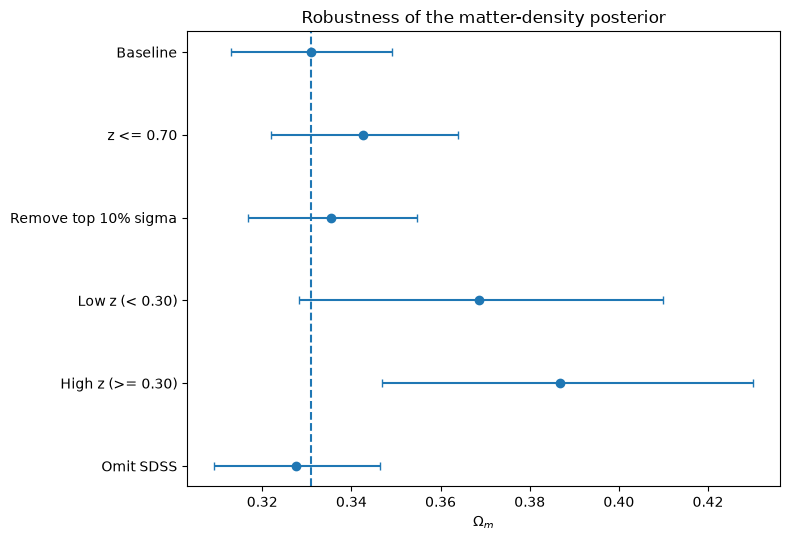

In [13]:
plot_table = results.copy()

y = np.arange(
    len(plot_table)
)

fig, ax = plt.subplots(
    figsize=(8, 5.5)
)

x = plot_table[
    "Omega_m_median"
].to_numpy()

xerr = np.vstack([
    x
    - plot_table[
        "Omega_m_16"
    ].to_numpy(),
    plot_table[
        "Omega_m_84"
    ].to_numpy()
    - x,
])

ax.errorbar(
    x,
    y,
    xerr=xerr,
    fmt="o",
    capsize=3,
)

ax.axvline(
    baseline_om[1],
    linestyle="--",
)

ax.set_yticks(
    y,
    plot_table[
        "variant"
    ],
)

ax.set_xlabel(
    r"$\Omega_m$"
)

ax.set_title(
    "Robustness of the matter-density posterior"
)

ax.invert_yaxis()

plt.tight_layout()
plt.show()

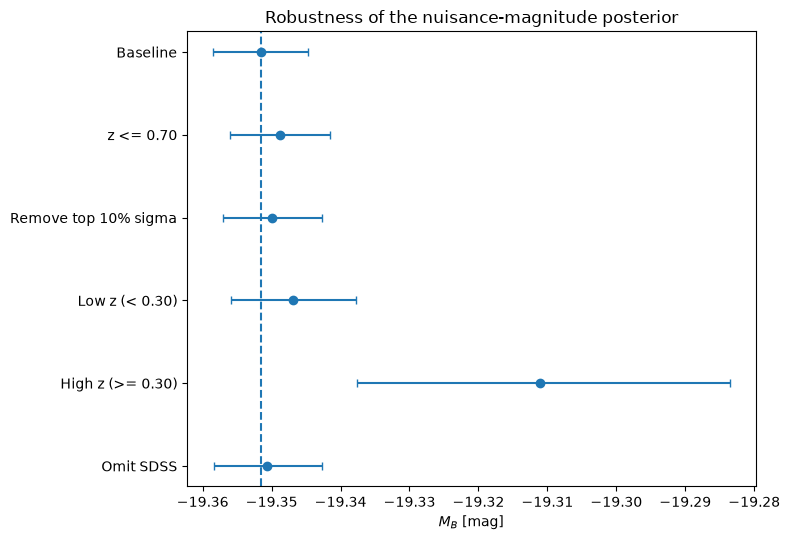

In [14]:
fig, ax = plt.subplots(
    figsize=(8, 5.5)
)

x = plot_table[
    "M_B_median"
].to_numpy()

xerr = np.vstack([
    x
    - plot_table[
        "M_B_16"
    ].to_numpy(),
    plot_table[
        "M_B_84"
    ].to_numpy()
    - x,
])

ax.errorbar(
    x,
    y,
    xerr=xerr,
    fmt="o",
    capsize=3,
)

ax.axvline(
    baseline_mb[1],
    linestyle="--",
)

ax.set_yticks(
    y,
    plot_table[
        "variant"
    ],
)

ax.set_xlabel(
    r"$M_B$ [mag]"
)

ax.set_title(
    "Robustness of the nuisance-magnitude posterior"
)

ax.invert_yaxis()

plt.tight_layout()
plt.show()

## In-class checkpoint

Before moving to the graded extension, show:

1. completed five-line scientific statement;
2. reproduced Lab 05 baseline;
3. sample-audit table;
4. full robustness results table;
5. $\Omega_m$ forest plot;
6. $M_B$ forest plot;
7. one-sentence identification of the largest tested
$|\Delta\Omega_m|$.

A plot without the numerical table is not a complete checkpoint.

# I. Diagnose the largest shift

A large shift is a **diagnostic result**, not an instruction to delete the corresponding observations.

Identify the non-baseline variant with the largest $|\Delta\Omega_m|.$

Then compare that sample with the baseline in at least three ways:

1. redshift distribution;
2. diagonal uncertainty distribution $\sqrt{C_{ii}}$;
3. survey composition.

If you want to use the word **outlier**, you must additionally examine a residual or influence diagnostic. A sample shift alone does not establish that any observation is an outlier.

In [15]:
nonbaseline = results[
    results["variant"]
    != "Baseline"
].copy()

largest_name = (
    nonbaseline
    .loc[
        nonbaseline[
            "Delta_Omega_m"
        ].abs().idxmax(),
        "variant",
    ]
)

print(
    "Largest absolute Omega_m shift:",
    largest_name,
)

largest_data, largest_cov = (
    variant_data[
        largest_name
    ]
)

comparison = pd.DataFrame({
    "quantity": [
        "N",
        "median z",
        "90th percentile z",
        "median sigma",
        "90th percentile sigma",
        "number of surveys",
    ],
    "baseline": [
        len(data0),
        data0["zHD"].median(),
        data0["zHD"].quantile(0.90),
        np.median(
            np.sqrt(
                np.diag(C0)
            )
        ),
        np.quantile(
            np.sqrt(
                np.diag(C0)
            ),
            0.90,
        ),
        data0["IDSURVEY"].nunique(),
    ],
    "largest-shift variant": [
        len(largest_data),
        largest_data["zHD"].median(),
        largest_data["zHD"].quantile(0.90),
        np.median(
            np.sqrt(
                np.diag(largest_cov)
            )
        ),
        np.quantile(
            np.sqrt(
                np.diag(largest_cov)
            ),
            0.90,
        ),
        largest_data[
            "IDSURVEY"
        ].nunique(),
    ],
})

display(
    comparison.round(5)
)

Largest absolute Omega_m shift: High z (>= 0.30)


,quantity,baseline,largest-shift variant
0,N,1580.00000,494.00000
1,median z,0.18518,0.44888
2,90th percentile z,0.56190,0.74820
3,median sigma,0.15348,0.16217
4,90th percentile sigma,0.23322,0.24907
5,number of surveys,20.00000,7.00000


## Exercise 3 — Largest-shift diagnosis

Produce **two diagnostic figures** and a 150–250 word interpretation.

At least one figure must address redshift or uncertainty distribution.

If the largest-shift variant is the survey omission, also show how the survey removal changes the redshift distribution.

Your interpretation must distinguish:
- what the data show;
- a plausible mechanism;
- what additional analysis would be needed to establish that mechanism.

**Answer based on our results and graphs**

We compared the baseline with the high-redshift sample ($z \geq 0.30$), which gives the largest shift in $\Omega_m$. The first figure shows their redshift and diagonal uncertainty distributions, using the same bins and fractions of each sample. The second shows the fraction of catalogue rows from each survey. Using fractions allows us to compare samples of different sizes.

The high-redshift sample contains 494 rows instead of 1580, and its median redshift increases from $0.18518$ to $0.44888$. The uncertainty distributions looks similar, although the median uncertainty increases from $0.15348$ to $0.16217$ mag.The survey composition also changes from 20 surveys to seven, with larger fractions from SNLS, DES and PS1MD.

For this sample, the median $\Omega_m$ increases from $0.330836$ to $0.386709$, while its 68% interval becomes wider. A possible explanation is that removing low-redshift observations loses information that helps separate $M_B$ from $\Omega_m$. Having fewer rows and slightly larger uncertainties could also widen the intervals. However, this does not establish why the median shifts upward.

To investigate the mechanism, we could compare surveys within the same redshift range and examine the joint posterior of $\Omega_m$ and $M_B$. This would help distinguish redshift effects from survey composition and parameter dependence. The observed shift shows sensitivity to the sample definition, not that the observations are invalid.

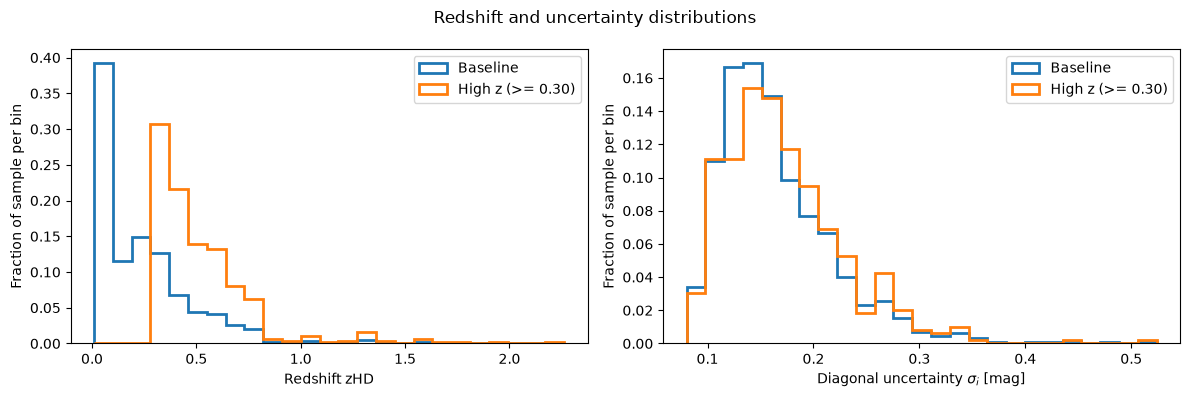

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparisons = [
    (
        data0["zHD"].to_numpy(),
        largest_data["zHD"].to_numpy(),
        "Redshift zHD",
    ),
    (
        np.sqrt(np.diag(C0)),
        np.sqrt(np.diag(largest_cov)),
        r"Diagonal uncertainty $\sigma_i$ [mag]",
    ),
]

for ax, (baseline_values, variant_values, label) in zip(
    axes, comparisons
):
    bins = np.linspace(
        min(baseline_values.min(), variant_values.min()),
        max(baseline_values.max(), variant_values.max()),
        26,
    )

    ax.hist(
        baseline_values,
        bins=bins,
        weights=np.ones(len(baseline_values)) / len(baseline_values),
        histtype="step",
        linewidth=2,
        label="Baseline",
    )
    ax.hist(
        variant_values,
        bins=bins,
        weights=np.ones(len(variant_values)) / len(variant_values),
        histtype="step",
        linewidth=2,
        label=largest_name,
    )

    ax.set_xlabel(label)
    ax.set_ylabel("Fraction of sample per bin")
    ax.legend()

fig.suptitle("Redshift and uncertainty distributions")
plt.tight_layout()
plt.show()

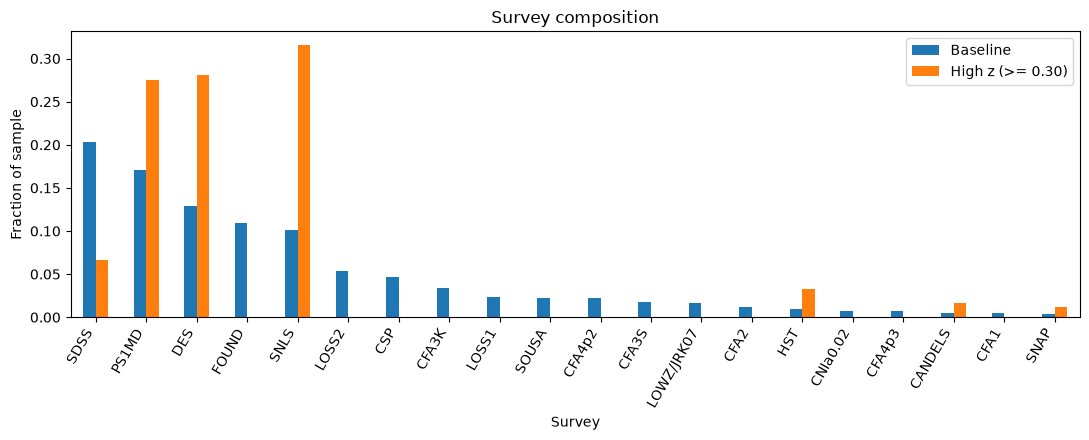

In [17]:
survey_fractions = pd.DataFrame({
    "Baseline": data0["IDSURVEY"].value_counts(normalize=True),
    largest_name: largest_data["IDSURVEY"].value_counts(normalize=True),
}).fillna(0)

survey_fractions = survey_fractions.sort_values(
    "Baseline", ascending=False
)

survey_fractions.index = [
    SURVEY_NAMES.get(survey_id, str(survey_id))
    for survey_id in survey_fractions.index
]

ax = survey_fractions.plot.bar(figsize=(11, 4.5))

ax.set_xlabel("Survey")
ax.set_ylabel("Fraction of sample")
ax.set_title("Survey composition")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

# J. Claims discipline

Use the table below when writing your conclusion.

| Statement | Supported by Lab 06? |
|---|---|
| “The result is stable under the tested perturbations.” | **Possibly**, if the numerical results support it |
| “Variant X gives the largest tested shift.” | **Yes**, if demonstrated |
| “The high-$z$ tail has strong leverage.” | **Possibly**, if diagnosed |
| “SDSS is wrong.” | **No** |
| “The observed sample is unbiased.” | **No** |
| “Malmquist bias has been removed.” | **No** |
| “The Pantheon+ selection function has been corrected.” | **No** |

Survey omission can reveal sensitivity to survey composition. It cannot by itself identify whether the mechanism is calibration, redshift coverage, precision, sample size or targeting.

# K. Extended Analysis — graded

Complete **all** tasks below independently.

The code for the baseline posterior and fixed perturbations is supplied so that the grade emphasizes scientific reasoning, statistical validity, robustness and reproducibility rather than boilerplate.

## E1 — Quantitative robustness table

Submit the complete table for all six compulsory sample definitions.

For each variant include:

- $N$;
- $\Omega_m$ median and central 68% interval;
- $\Omega_m$ interval width;
- $\Delta\Omega_m$ from baseline;
- descriptive normalized shift $R$;
- $M_B$ median and central 68% interval;
- $\Delta M_B$ from baseline.

Include **two quantitative sentences** describing the largest changes.

Do not call $R$ a “number of sigma tension”.

## E2 — Largest-shift diagnosis

Identify the largest $
|\Delta\Omega_m|.
$

Compare the corresponding sample with baseline using:

- redshift distribution;
- diagonal uncertainty distribution;
- survey composition.

Explain whether the evidence points most strongly toward redshift leverage, precision composition, survey composition, or a mixture.

If the mechanism is not identifiable from these diagnostics, say so.

## E3 — Influence versus invalid data

Answer in 150–250 words.

1. Why does a large parameter shift after removing a subset imply **influence/sensitivity**, not automatically invalid data?
2. What additional diagnostic would you require before describing individual observations as outliers?
3. If omitting SDSS causes a shift, why could survey and redshift effects be confounded?

## E4 — Sensitivity versus formal selection correction

Starting from

$$
p(D\mid\theta,S=1)
=
\frac{
p(S=1\mid D,\theta)\,p(D\mid\theta)
}{
P(S=1\mid\theta)
},
$$

explain which quantities required for a formal selection correction are **not estimated in this lab**.

Then explain precisely what the sample perturbations *do* establish.

## E5 — Scientific conclusion (300–500 words)

In connected scientific prose answer:

- What was inferred?
- What baseline sample/model/covariance was conditioned upon?
- Which perturbation produced the largest tested shift?
- How large was that shift?
- Which aspect of the result was most stable?
- What diagnostic evidence helps explain the largest shift?
- What is the dominant limitation of this robustness exercise?
- Why is the result a sensitivity statement rather than a selection-function
correction?
- What stronger assertion would be unjustified?

### Required final sentence

> **“From this lab we can conclude ___, conditional on ___, but we cannot
> conclude ___.”**

## Student workspace for E1–E4

Add your code, tables, figures and explanations below. Label all axes and state units where relevant.

### E1 — Quantitative robustness table


In [18]:
with pd.option_context("display.max_columns", None):
    display(results.round(6))

,variant,N,Omega_m_median,Omega_m_16,Omega_m_84,Omega_m_width,Delta_Omega_m,R_abs_shift,M_B_median,M_B_16,M_B_84,M_B_width,Delta_M_B,edge_mass
0,Baseline,1580,0.330836,0.312934,0.349201,0.036267,0.000000,0.000000,-19.351608,-19.358508,-19.344675,0.013833,0.000000,0.000000
1,z <= 0.70,1505,0.342704,0.321956,0.363942,0.041986,0.011867,0.654441,-19.348851,-19.356090,-19.341570,0.014519,0.002756,0.000000
2,Remove top 10% sigma,1422,0.335504,0.316849,0.354621,0.037772,0.004668,0.257407,-19.349900,-19.357041,-19.342719,0.014322,0.001708,0.000000
3,Low z (< 0.30),1086,0.368585,0.328241,0.409956,0.081715,0.037749,2.081731,-19.346846,-19.355883,-19.337759,0.018124,0.004762,0.000000
4,High z (>= 0.30),494,0.386709,0.346784,0.430103,0.083320,0.055873,3.081197,-19.311024,-19.337550,-19.283474,0.054076,0.040584,0.000002
5,Omit SDSS,1259,0.327559,0.309182,0.346417,0.037235,-0.003278,0.180758,-19.350610,-19.358423,-19.342762,0.015661,0.000998,0.000000


The high-redshift sample gives the largest shift in $\Omega_m$: its median increases from $0.330836$ to $0.386709$, with $\Delta\Omega_m=0.055873$ and a descriptive normalized shift of $R=3.081197$, while its 68% interval width increases from $0.036267$ to $0.083320$.

The same sample also gives the largest shift in $M_B$: its median increases from $-19.351608$ to $-19.311024$ mag, a change of $0.040584$ mag, while its central 68% interval widens from $[-19.358508,-19.344675]$ to $[-19.337550,-19.283474]$ mag.

R is descriptive rather than a formal tension significance because each variant shares observations with the baseline.

### E2 — Largest-shift diagnosis

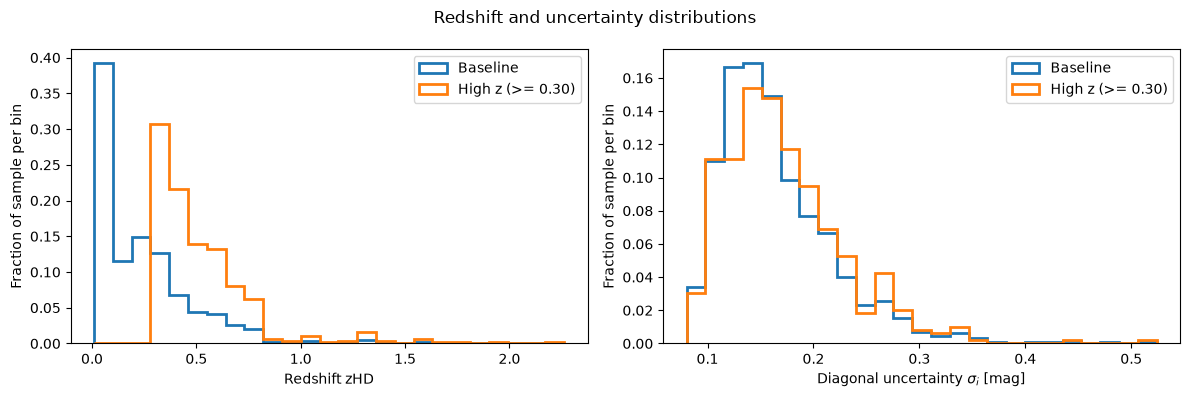

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparisons = [
    (
        data0["zHD"].to_numpy(),
        largest_data["zHD"].to_numpy(),
        "Redshift zHD",
    ),
    (
        np.sqrt(np.diag(C0)),
        np.sqrt(np.diag(largest_cov)),
        r"Diagonal uncertainty $\sigma_i$ [mag]",
    ),
]

for ax, (baseline_values, variant_values, label) in zip(
    axes, comparisons
):
    bins = np.linspace(
        min(baseline_values.min(), variant_values.min()),
        max(baseline_values.max(), variant_values.max()),
        26,
    )

    ax.hist(
        baseline_values,
        bins=bins,
        weights=np.ones(len(baseline_values)) / len(baseline_values),
        histtype="step",
        linewidth=2,
        label="Baseline",
    )
    ax.hist(
        variant_values,
        bins=bins,
        weights=np.ones(len(variant_values)) / len(variant_values),
        histtype="step",
        linewidth=2,
        label=largest_name,
    )

    ax.set_xlabel(label)
    ax.set_ylabel("Fraction of sample per bin")
    ax.legend()

fig.suptitle("Redshift and uncertainty distributions")
plt.tight_layout()
plt.show()

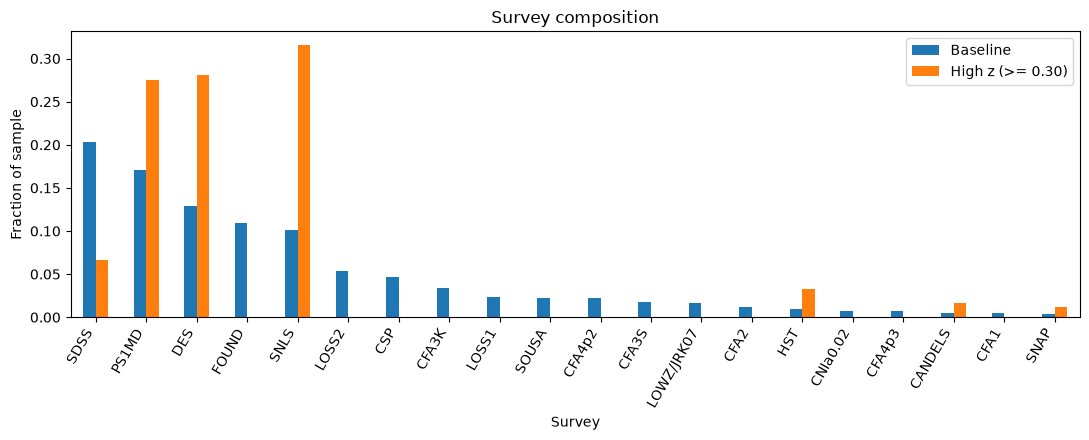

In [20]:
survey_fractions = pd.DataFrame({
    "Baseline": data0["IDSURVEY"].value_counts(normalize=True),
    largest_name: largest_data["IDSURVEY"].value_counts(normalize=True),
}).fillna(0)

survey_fractions = survey_fractions.sort_values(
    "Baseline", ascending=False
)

survey_fractions.index = [
    SURVEY_NAMES.get(survey_id, str(survey_id))
    for survey_id in survey_fractions.index
]

ax = survey_fractions.plot.bar(figsize=(11, 4.5))

ax.set_xlabel("Survey")
ax.set_ylabel("Fraction of sample")
ax.set_title("Survey composition")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

The high-redshift sample ($z \geq 0.30$) gives the largest absolute shift, $|\Delta\Omega_m|=0.055873$.

Compared with baseline, the median redshift increases from $0.18518$ to $0.44888$, and the sample decreases from 1580 to 494 rows. The diagonal uncertainty distributions look similar, although the median increases from $0.15348$ to $0.16217$ mag. Survey composition also changes: only seven of the original 20 surveys remain, with larger fractions from SNLS, DES and PS1MD.

The clearest differences are in redshift coverage and survey composition, suggesting a mixture of these effects rather than precision alone. Removing the low-redshift observations could reduce the information that helps separate $M_B$ from $\Omega_m$, while the smaller sample could also contribute to wider intervals. However, these diagnostics do not identify the cause of the upward shift, because several sample properties change together. Comparing surveys within the same redshift range would help investigate this further.

### E3 — Influence versus invalid data

A large parameter shift after removing a part of the sample shows that the result depends on those observations. It does not automatically mean that the data are invalid. The subset may cover a useful redshift range, contain precise measurements, or include many observations. Removing it changes the information available to the fit, even if every measurement is valid. In our results, the high-redshift sample produces the largest shift, but this alone does not identify any individual observation as an outlier.

Before calling an observation an outlier, I would check how far its measured magnitude is from the model prediction, taking the uncertainties and full covariance into account. I could also repeat the fit without that observation to see how much the result changes. However, changing the result would show that it is influential, not necessarily that it is an outlier.

If removing SDSS changes the result, it could be because of the redshift range it covers. We are changing both which surveys are included and the redshift distribution, so it is difficult to separate the two effects. This does not mean there is a problem with SDSS. Comparing surveys over the same redshift range could help us understand what causes the change.

### E4 — Sensitivity versus formal selection correction

This lab does not estimate $p(S=1\mid D,\theta)$, the probability that an object is selected given its data and the model parameters, or $P(S=1\mid\theta)$, the overall probability of entering the catalogue under the model. Without these terms, we cannot make a formal selection correction.

The sample changes show how much the inferred $\Omega_m$ and $M_B$, and their uncertainties, depend on which observations we include. Since we keep the model, priors and fitting method fixed, we can identify which tested change affects the result most. However, this does not establish why the shift occurs or show that the sample is unbiased.

## E5 — Scientific conclusion

In this lab, we used Pantheon+ data to infer $\Omega_m$ and the nuisance parameter $M_B$. We wanted to check how much the results change when we change which observations are included. The baseline used non-calibrator rows with $z_{\rm HD}>0.01$ and finite zHD and m_b_corr, together with the full STAT+SYS covariance. We kept repeated rows and their correlations. We used a flat matter–$\Lambda$ model, with $H_0=70$ as a zero-point convention, and kept the same priors, grid and fitting method for every sample.

The baseline agreed with the Lab 05 fine-grid results to the precision shown. The median $\Omega_m$ was $0.330836$, with a central 68% interval of $[0.312934,0.349201]$. The median $M_B$ was $-19.351608$ mag. The high-redshift sample ($z\geq0.30$) gave the largest change: $\Omega_m$ increased to $0.386709$, a shift of $0.055873$. Its interval width also increased from $0.036267$ to $0.083320$, so the result changed and became less precise. This sample also gave the largest shift in $M_B$, increasing its median by $0.040584$ mag.

The results stayed closest to baseline when we removed SDSS or the 10% of rows with the largest uncertainties. These changes moved $\Omega_m$ by $-0.003278$ and $0.004668$, respectively. This suggests that the result is fairly stable under these two changes, although the redshift splits have a larger effect.

To understand the largest shift, we compared the redshift and uncertainty distributions and the survey composition. The high-redshift sample has 494 rows instead of 1580, and its median redshift increases from $0.18518$ to $0.44888$. The uncertainty distributions look similar, but the median uncertainty is slightly higher. Only seven of the original 20 surveys remain, with larger fractions from SNLS, DES and PS1MD. Losing low-redshift information could make it harder to separate $M_B$ from $\Omega_m$, and having fewer observations could help explain the wider intervals. However, these comparisons do not establish why the median moves upward.

The main limitation is that several things change together, so we cannot separate their effects from these figures alone. We also do not calculate the selection probabilities needed to correct how objects entered the catalogue. We therefore cannot say that the sample is unbiased, that a survey is wrong, or that Malmquist bias has been removed.

From this lab we can conclude that the high redshift only sample gives the largest tested change in the inferred parameters, conditional on our baseline sample, model, priors and STAT+SYS covariance, but we cannot conclude that we have corrected the survey selection function.

# Submission and grading checklist

Before submission:

- restart the kernel;
- run all cells from top to bottom;
- resolve every incomplete exercise;
- keep the official data provenance visible;
- export the same executed notebook as HTML/PDF;
- submit `Surname_Name_L06.ipynb` plus that export.

| Dimension | Weight | Evidence expected |
|---|---:|---|
| Scientific formulation | 20% | Specific estimand, model, covariance, sample conditioning and limitation |
| Statistical correctness | 25% | Correct masks, covariance slicing, fixed posterior engine and shift definitions |
| Uncertainty quantification | 20% | 68% intervals, widths, absolute shifts and careful interpretation of $R$ |
| Diagnostics / failure analysis | 15% | Baseline validation, largest-shift diagnosis, influence/selection reasoning |
| Reproducibility | 10% | Prespecified perturbations, official data, full execution, readable tables/plots |
| Scientific interpretation | 10% | 300–500 word conclusion with supported and unsupported claims separated |

### Scientific scope

This notebook is a teaching robustness analysis. It is not an official Pantheon+ cosmology reproduction, an independent $H_0$ measurement, or a formal selection-function correction.